# Is the Limitation the Model or the Molecular Representation?

We compare **three prespecified variants** on the same dataset, scaffold test partition, and five training CV folds.

1. **Random Forest + Morgan fingerprints** — control.
2. **RBF SVM + the same Morgan fingerprints** — change model family only.
3. **Random Forest + fingerprints + six descriptors** — change input information only.

The objective remains **training OOF precision ≥ 90%, then maximum recall**. Model and threshold selection use training OOF scores only. Only the selected candidate is evaluated on test. Select **Run All**.

This is a bounded experiment, not a definitive comparison of all SVMs or representations. The same test set has already been inspected; this is not new independent validation.

**Later tuning:** notebook 07 compares further settings against this experiment's selected descriptor RF. Activation details below describe the outcome at this stage.

## 1. What changed?

The SVM uses an RBF kernel, `C=1`, `gamma="scale"`, and balanced class weights. The kernel learns a nonlinear boundary over fingerprints. Gamma is derived only from each training subset.

For RF, we append molecular weight, cLogP, TPSA, hydrogen-bond donor and acceptor counts, and rotatable bond count. RF settings match the control. These calculated descriptors do not require scaling for the tree model.

All three candidates receive the same 2054-column input, but fingerprint-only pipelines explicitly discard the last six columns.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay)

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open from the project root or notebooks directory.")
sys.path.insert(0, str(ROOT))
from src.modeling import select_model_at_precision
candidate_path = ROOT / "models/herg_representation_candidate.joblib"
baseline_path = ROOT / "models/herg_precision_baseline.joblib"
if not candidate_path.is_file() or not baseline_path.is_file():
    raise FileNotFoundError("Run the representation experiment and retain the baseline first; see README.")
a = joblib.load(candidate_path)  # Only load trusted local artifacts.
old = joblib.load(baseline_path)
assert a["representation_search"] and a["include_descriptors"]
assert a["dataset_sha256"] == old["dataset_sha256"] == sha256((ROOT / "data/raw/herg_karim.csv").read_bytes()).hexdigest()
oof = a["oof_predictions"]
test = a["test_predictions"]
target = a["threshold_selection"]["min_precision"]
assert target == old["threshold_selection"]["min_precision"]
assert oof.row_index.is_unique
assert set(oof.row_index) == set(a["train_indices"])
assert set(oof.row_index) == set(old["train_indices"])
assert set(test.row_index) == set(old["test_predictions"].row_index)
assert set(oof.row_index).isdisjoint(test.row_index)
assert set(oof.scaffold).isdisjoint(test.scaffold)
assert oof.groupby("scaffold").fold.nunique().eq(1).all()
selected, policies = select_model_at_precision(a["cv_metrics"], a["candidate_oof_scores"], oof.label, target)
assert selected == a["model_name"]
assert policies == a["candidate_thresholds"]
assert policies[selected] == a["threshold_selection"]
# Verify the control reproduces the earlier fingerprint-only RF OOF scores.
previous_oof = old["oof_predictions"].set_index("row_index").loc[oof.row_index]
np.testing.assert_allclose(a["candidate_oof_scores"]["Random forest (fingerprints)"], previous_oof.score)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
display(pd.Series({"Selected model": selected, "Selected threshold": a["decision_threshold"],
    "Input columns": a["model"].n_features_in_, "Score method": a["score_method"],
    "OOF rows": len(oof), "Test rows": len(test)}, name="Experiment").to_frame())

,Experiment
Selected model,Random forest (fingerprints + descriptors)
Selected threshold,0.647325
Input columns,2054
Score method,probability
OOF rows,10765
Test rows,2680


## 2. Training comparison of all three variants

All candidate results here are OOF, not test. Each model gets its own selected threshold. Recall is the primary selection metric after satisfying the precision constraint.

**SVM score interpretation:** we apply a sigmoid to the decision margin to express scores in [0, 1]. This is not calibration; a score of 0.9 does not mean “90% probability.” The transformation preserves ranking, which determines PR/AP and available decision sets. Numerical thresholds are not directly comparable across model families.

,OOF precision,OOF recall,Threshold,Mean CV AP,CV AP SD,Selected
Model,,,,,,
Random forest (fingerprints),0.9006,0.5342,0.6720,0.8757,0.0120,False
RBF SVM (fingerprints),0.9005,0.4948,0.6390,0.8661,0.0092,False
Random forest (fingerprints + descriptors),0.9009,0.5871,0.6473,0.8888,0.0063,True


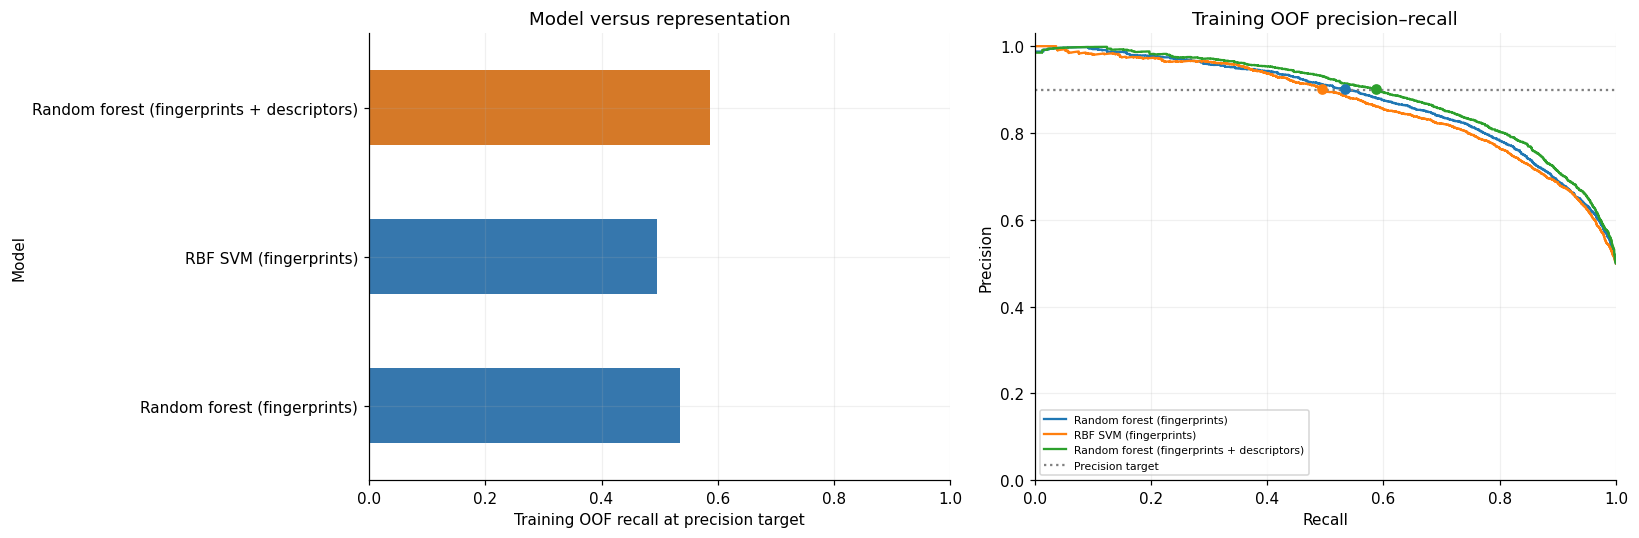

,OOF recall change versus fingerprint RF
Random forest (fingerprints),0.0000
RBF SVM (fingerprints),-0.0394
Random forest (fingerprints + descriptors),0.0528


In [2]:
rows = []
for name, policy in policies.items():
    rows.append({"Model": name, "OOF precision": policy.get("precision", np.nan),
        "OOF recall": policy.get("recall", np.nan), "Threshold": policy.get("threshold", np.nan),
        "Mean CV AP": a["cv_metrics"][name]["auprc"]["mean"],
        "CV AP SD": a["cv_metrics"][name]["auprc"]["std"], "Selected": name == selected})
training = pd.DataFrame(rows).set_index("Model")
display(training.round(4))
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
training["OOF recall"].plot.barh(ax=axes[0], color=["#d57928" if name == selected else "#3677ad" for name in training.index])
axes[0].set(xlabel="Training OOF recall at precision target", xlim=(0, 1), title="Model versus representation")
for name, scores in a["candidate_oof_scores"].items():
    precision, recall, _ = precision_recall_curve(oof.label, scores)
    axes[1].step(recall, precision, where="post", label=name)
    policy = policies[name]
    if "threshold" in policy:
        axes[1].scatter(policy["recall"], policy["precision"], zorder=4)
axes[1].axhline(target, color="gray", linestyle=":", label="Precision target")
axes[1].set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.03), title="Training OOF precision–recall")
axes[1].legend(fontsize=7, loc="lower left")
fig.tight_layout()
plt.show()
control = policies["Random forest (fingerprints)"]
if "threshold" in control:
    display(pd.Series({name: policy["recall"] - control["recall"]
        for name, policy in policies.items() if "threshold" in policy},
        name="OOF recall change versus fingerprint RF").to_frame().round(4))

## 3. Test results for the training-selected winner only

We compare the previous precision RF model with this experiment's training-selected winner only. Test results for the other candidates are not computed, so they cannot drive model selection.

Test precision need not satisfy the 90% target. The training-selected threshold is not adjusted in response to test results.

,Precision,Recall,F1,TN,FP,FN,TP
Run,,,,,,,
Previous RF precision model,0.9142,0.5797,0.7095,1265,73,564,778
Experiment winner,0.9059,0.6453,0.7537,1248,90,476,866


,Winner minus previous
Precision,-0.0084
Recall,0.0656
F1,0.0442
TN,-17.0000
FP,17.0000
FN,-88.0000
TP,88.0000


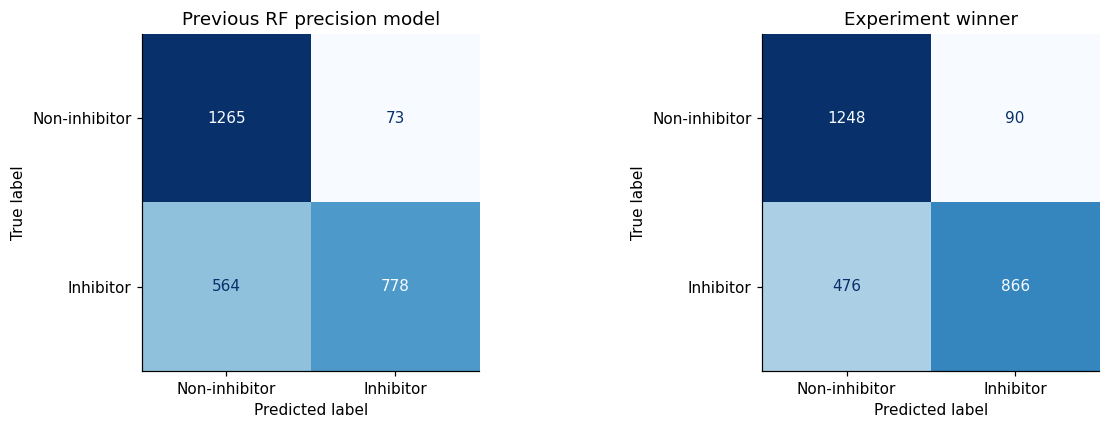

In [3]:
test_rows = []
for name, artifact in [("Previous RF precision model", old), ("Experiment winner", a)]:
    data = artifact["test_predictions"]
    prediction = data.threshold_prediction
    np.testing.assert_array_equal(prediction, data.score >= artifact["decision_threshold"])
    tn, fp, fn, tp = confusion_matrix(data.label, prediction, labels=[0, 1]).ravel()
    test_rows.append({"Run": name,
        "Precision": precision_score(data.label, prediction, zero_division=0),
        "Recall": recall_score(data.label, prediction, zero_division=0),
        "F1": f1_score(data.label, prediction, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp})
comparison = pd.DataFrame(test_rows).set_index("Run")
display(comparison.round(4))
display((comparison.iloc[1] - comparison.iloc[0]).rename("Winner minus previous").to_frame().round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, title, artifact in zip(axes, comparison.index, [old, a]):
    data = artifact["test_predictions"]
    ConfusionMatrixDisplay.from_predictions(data.label, data.threshold_prediction, labels=[0, 1],
        display_labels=["Non-inhibitor", "Inhibitor"], cmap="Blues", ax=ax, colorbar=False, values_format="d")
    ax.set_title(title)
    ax.grid(False)
fig.tight_layout()
plt.show()

## 4. What can we conclude?

- The SVM–control RF difference concerns a model-family change at these particular settings. It does not prove superiority or inferiority of all SVMs.
- The descriptor RF–control RF difference measures adding these six descriptors at the same settings.
- The best OOF result is a selection estimate, not independent validation.
- If test results do not improve, we do not relax the target or search for a new test-driven threshold.
- App inference must use the same feature vector and scoring method. The code now supports both, but an experimental artifact is not automatically active.

## Outcome of this run

Adding descriptors helped in this experiment. Training OOF recall at the 90% precision target was **53.42%** for control RF, **49.48%** for this RBF SVM, and **58.71%** for descriptor RF. This supports enriching the representation at these settings; it does not establish that SVMs generally perform worse.

On the already inspected test set, the training-selected descriptor RF achieved **90.59% precision** and **64.53% recall**, versus the previous model's **91.42%** and **57.97%**. False negatives decreased **564 → 476** (88 more inhibitors detected), while false positives increased **73 → 90** (17 more false alarms).

The new threshold is **0.647325**. The app now uses the descriptor RF; the old model remains in `herg_precision_baseline.joblib`. Both policies exceed 90% precision in this observed test comparison, but precision decreased slightly. This does not guarantee future performance and is not fresh independent validation.